# Experiment 14: Unfolded RNN Architecture Visualization

A speech-analytics engineer wants to see the recurrent loop unfolded across a five-word sentence. We pass five fixed word vectors through a three-unit Keras SimpleRNN, reproduce the hidden states manually and draw the unrolled graph.

**Tools:** TensorFlow, Keras, NetworkX, Matplotlib, NumPy.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Build a SimpleRNN and extract input, recurrent and output weights.  2. Compute hidden states manually and compare with Keras.  3. Draw x₁…x₅, h₁…h₅ and y₁…y₅ with shared-weight edge labels.  4. Plot hidden-state values over time.

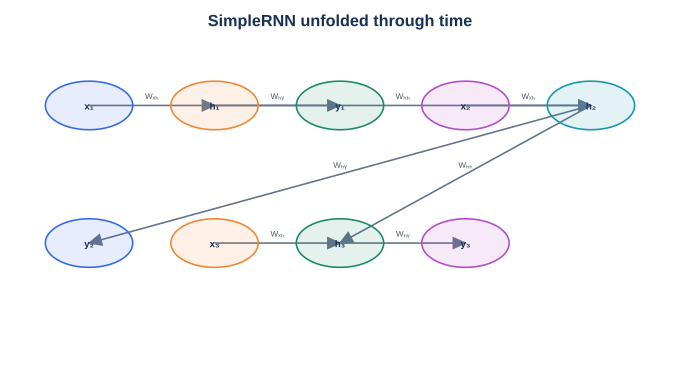

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import networkx as nx

tf.keras.utils.set_random_seed(14)
words=["Deep","models","learn","from","sequences"]
# Each word is represented by a small, fixed 4-D embedding.
x=np.array([[.2,.1,.8,.3],[.7,.2,.1,.4],[.4,.8,.2,.1],[.1,.3,.5,.9],[.6,.4,.2,.3]],dtype="float32")[None,:,:]
rnn=tf.keras.layers.SimpleRNN(3,return_sequences=True,activation="tanh",use_bias=True)
dense=tf.keras.layers.Dense(1)
states=rnn(x); outputs=dense(states)
Wxh,Whh,bias=rnn.get_weights()
Why,by=dense.get_weights()
manual=[]; h=np.zeros(3,dtype="float32")
for t in range(x.shape[1]):
    h=np.tanh(x[0,t]@Wxh + h@Whh + bias)
    manual.append(h.copy())
manual=np.array(manual)
print("Max hidden-state difference (manual vs Keras):",np.max(np.abs(manual-states.numpy()[0])))
print("Extracted shapes: W_xh",Wxh.shape,"W_hh",Whh.shape,"W_hy",Why.shape)

G=nx.DiGraph()
for t,w in enumerate(words,1):
    G.add_node(f"x{t}",label=f"x{t}\\n{w}",layer=0)
    G.add_node(f"h{t}",label=f"h{t}",layer=1)
    G.add_node(f"y{t}",label=f"y{t}",layer=2)
    G.add_edge(f"x{t}",f"h{t}",label="W_xh")
    if t>1:G.add_edge(f"h{t-1}",f"h{t}",label="W_hh")
    G.add_edge(f"h{t}",f"y{t}",label="W_hy")
pos={f"x{t}":(t,2) for t in range(1,6)}
pos.update({f"h{t}":(t,1) for t in range(1,6)})
pos.update({f"y{t}":(t,0) for t in range(1,6)})
labels={n:d["label"] for n,d in G.nodes(data=True)}
plt.figure(figsize=(11,4))
nx.draw_networkx_nodes(G,pos,node_size=950,node_color=["#d9edf7" if n[0]=="x" else "#dff0d8" if n[0]=="h" else "#fcf8e3" for n in G])
nx.draw_networkx_labels(G,pos,labels=labels,font_size=8)
nx.draw_networkx_edges(G,pos,arrows=True,arrowsize=14)
nx.draw_networkx_edge_labels(G,pos,edge_labels=nx.get_edge_attributes(G,"label"),font_size=7)
plt.title("SimpleRNN unfolded over five time steps");plt.axis("off");plt.show()
plt.figure(figsize=(7,3))
for unit in range(3):plt.plot(range(1,6),manual[:,unit],marker="o",label=f"hidden unit {unit+1}")
plt.xticks(range(1,6),words);plt.xlabel("Time step");plt.ylabel("Hidden activation")
plt.title("Hidden-state values");plt.legend();plt.tight_layout();plt.show()